# Business Problem

LoanTap needs an automated underwriting layer for its Personal Loan product: given a borrower's application attributes, decide whether to extend credit and, if so, on what terms. This is a binary classification problem where we need to predict whether a loan will be Fully Paid (1) or Charged Off (0) — using Logistic Regression, so that LoanTap can convert model output into a go/no-go decision and provide pricing/terms recommendations.

## Import Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score, roc_curve, precision_recall_curve,
                            average_precision_score, f1_score, accuracy_score, precision_score, recall_score)

from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

import warnings
warnings.filterwarnings("ignore")

# from google.colab import drive
# drive.mount('/content/drive')

## Load Dataset

In [ ]:
df = pd.read_csv('logistic_regression.csv')

In [ ]:
df.head(5)

,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,...,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies,address
0,10000.0,36 months,11.44,329.48,B,B4,Marketing,10+ years,RENT,117000.0,...,16.0,0.0,36369.0,41.8,25.0,w,INDIVIDUAL,0.0,0.0,"0174 Michelle Gateway\r\nMendozaberg, OK 22690"
1,8000.0,36 months,11.99,265.68,B,B5,Credit analyst,4 years,MORTGAGE,65000.0,...,17.0,0.0,20131.0,53.3,27.0,f,INDIVIDUAL,3.0,0.0,"1076 Carney Fort Apt. 347\r\nLoganmouth, SD 05113"
2,15600.0,36 months,10.49,506.97,B,B3,Statistician,< 1 year,RENT,43057.0,...,13.0,0.0,11987.0,92.2,26.0,f,INDIVIDUAL,0.0,0.0,"87025 Mark Dale Apt. 269\r\nNew Sabrina, WV 05113"
3,7200.0,36 months,6.49,220.65,A,A2,Client Advocate,6 years,RENT,54000.0,...,6.0,0.0,5472.0,21.5,13.0,f,INDIVIDUAL,0.0,0.0,"823 Reid Ford\r\nDelacruzside, MA 00813"
4,24375.0,60 months,17.27,609.33,C,C5,Destiny Management Inc.,9 years,MORTGAGE,55000.0,...,13.0,0.0,24584.0,69.8,43.0,f,INDIVIDUAL,1.0,0.0,"679 Luna Roads\r\nGreggshire, VA 11650"


## Data Dictionary

In [ ]:
data_dictionary = pd.DataFrame({
"Column": ['loan_amnt ','term ','int_rate ','installment ','grade ','sub_grade ','emp_title ','emp_length ','home_ownership ','annual_inc ','verification_status ','issue_d ','loan_status ','purpose ','title ','dti ','earliest_cr_line ','open_acc ','pub_rec ','revol_bal ','revol_util ','total_acc ','initial_list_status ','application_type ','mort_acc ','pub_rec_bankruptcies ','Address'],
"Description": ["The listed amount of the loan applied for by the borrower. If at some point in time, the credit department reduces the loan amount, then it will be reflected in this value.",
"The number of payments on the loan. Values are in months and can be either 36 or 60.",
"Interest Rate on the loan",
"The monthly payment owed by the borrower if the loan originates.",
"LoanTap assigned loan grade",
"LoanTap assigned loan subgrade",
"The job title supplied by the Borrower when applying for the loan.*",
"Employment length in years. Possible values are between 0 and 10 where 0 means less than one year and 10 means ten or more years.",
"The home ownership status provided by the borrower during registration or obtained from the credit report.",
"The self-reported annual income provided by the borrower during registration.",
"Indicates if income was verified by LoanTap, not verified, or if the income source was verified",
"The month which the loan was funded",
"Current status of the loan - Target Variable",
"A category provided by the borrower for the loan request.",
"The loan title provided by the borrower",
"A ratio calculated using the borrower’s total monthly debt payments on the total debt obligations, excluding mortgage and the requested LoanTap loan, divided by the borrower’s self-reported monthly income.",
"The month the borrower's earliest reported credit line was opened",
"The number of open credit lines in the borrower's credit file.",
"Number of derogatory public records",
"Total credit revolving balance",
"Revolving line utilization rate, or the amount of credit the borrower is using relative to all available revolving credit.",
"The total number of credit lines currently in the borrower's credit file",
"The initial listing status of the loan. Possible values are – W, F",
"Indicates whether the loan is an individual application or a joint application with two co-borrowers",
"Number of mortgage accounts.",
"Number of public record bankruptcies",
"Address of the individual"]})

display(data_dictionary)

,Column,Description
0,loan_amnt,The listed amount of the loan applied for by t...
1,term,The number of payments on the loan. Values are...
2,int_rate,Interest Rate on the loan
3,installment,The monthly payment owed by the borrower if th...
4,grade,LoanTap assigned loan grade
5,sub_grade,LoanTap assigned loan subgrade
6,emp_title,The job title supplied by the Borrower when ap...
7,emp_length,Employment length in years. Possible values ar...
8,home_ownership,The home ownership status provided by the borr...
9,annual_inc,The self-reported annual income provided by th...


## Basic Structure and Characteristics

In [ ]:
df.shape

(396030, 27)

**Dataset**: 396,030 historical personal loans, 27 attributes.

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 396030 entries, 0 to 396029
Data columns (total 27 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   loan_amnt             396030 non-null  float64
 1   term                  396030 non-null  str    
 2   int_rate              396030 non-null  float64
 3   installment           396030 non-null  float64
 4   grade                 396030 non-null  str    
 5   sub_grade             396030 non-null  str    
 6   emp_title             373103 non-null  str    
 7   emp_length            377729 non-null  str    
 8   home_ownership        396030 non-null  str    
 9   annual_inc            396030 non-null  float64
 10  verification_status   396030 non-null  str    
 11  issue_d               396030 non-null  str    
 12  loan_status           396030 non-null  str    
 13  purpose               396030 non-null  str    
 14  title                 394274 non-null  str    
 15  dti        

In [ ]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
loan_amnt,396030.0,14113.888089,8357.441341,500.00,8000.00,12000.00,20000.00,40000.00
int_rate,396030.0,13.639400,4.472157,5.32,10.49,13.33,16.49,30.99
installment,396030.0,431.849698,250.727790,16.08,250.33,375.43,567.30,1533.81
annual_inc,396030.0,74203.175798,61637.621158,0.00,45000.00,64000.00,90000.00,8706582.00
dti,396030.0,17.379514,18.019092,0.00,11.28,16.91,22.98,9999.00
open_acc,396030.0,11.311153,5.137649,0.00,8.00,10.00,14.00,90.00
pub_rec,396030.0,0.178191,0.530671,0.00,0.00,0.00,0.00,86.00
revol_bal,396030.0,15844.539853,20591.836109,0.00,6025.00,11181.00,19620.00,1743266.00
revol_util,395754.0,53.791749,24.452193,0.00,35.80,54.80,72.90,892.30
total_acc,396030.0,25.414744,11.886991,2.00,17.00,24.00,32.00,151.00


## Convert categoricals to category data type

In [ ]:
cat_cols = ["term", "grade", "sub_grade", "home_ownership", "verification_status",
            "loan_status", "purpose", "initial_list_status", "application_type"]
for c in cat_cols:
    df[c] = df[c].astype("category")

## Target Variable

In [ ]:
status_counts = df["loan_status"].value_counts()
status_pct = df['loan_status'].value_counts(normalize=True) * 100

print(status_counts)
print(" ")
print(status_pct.round(2))

loan_status
Fully Paid     318357
Charged Off     77673
Name: count, dtype: int64
 
loan_status
Fully Paid     80.39
Charged Off    19.61
Name: proportion, dtype: float64


**Observation:** 80.39% of the customers have fully paid their loan, 19.61% Charged Off. This is a highly **imbalanced data**. This imbalance means plain accuracy is a misleading metric (a model that always predicts "Fully Paid" would score ~80% accuracy while catching zero defaulters)

### Conversion of Target Variable to Binary

**Considered**

1 = Fully Paid (good)

0 = Charged Off (defaulter)

In [ ]:
df["loan_repaid"] = df["loan_status"].astype(str).map({"Fully Paid": 1, "Charged Off": 0}).astype(int)

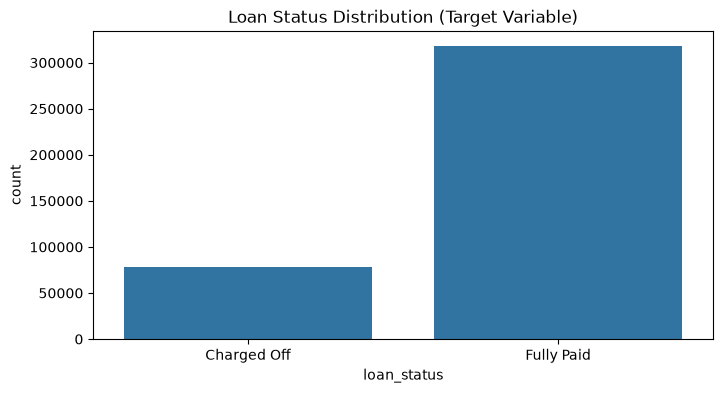

In [ ]:
plt.figure(figsize=(8, 4))
sns.countplot(x="loan_status", data=df)
plt.title("Loan Status Distribution (Target Variable)")
plt.show()

## Univariate Analysis

### Continuous Variables

In [ ]:
num_cols = df.select_dtypes(include=['float', 'int']).drop('loan_repaid', axis = 1).columns

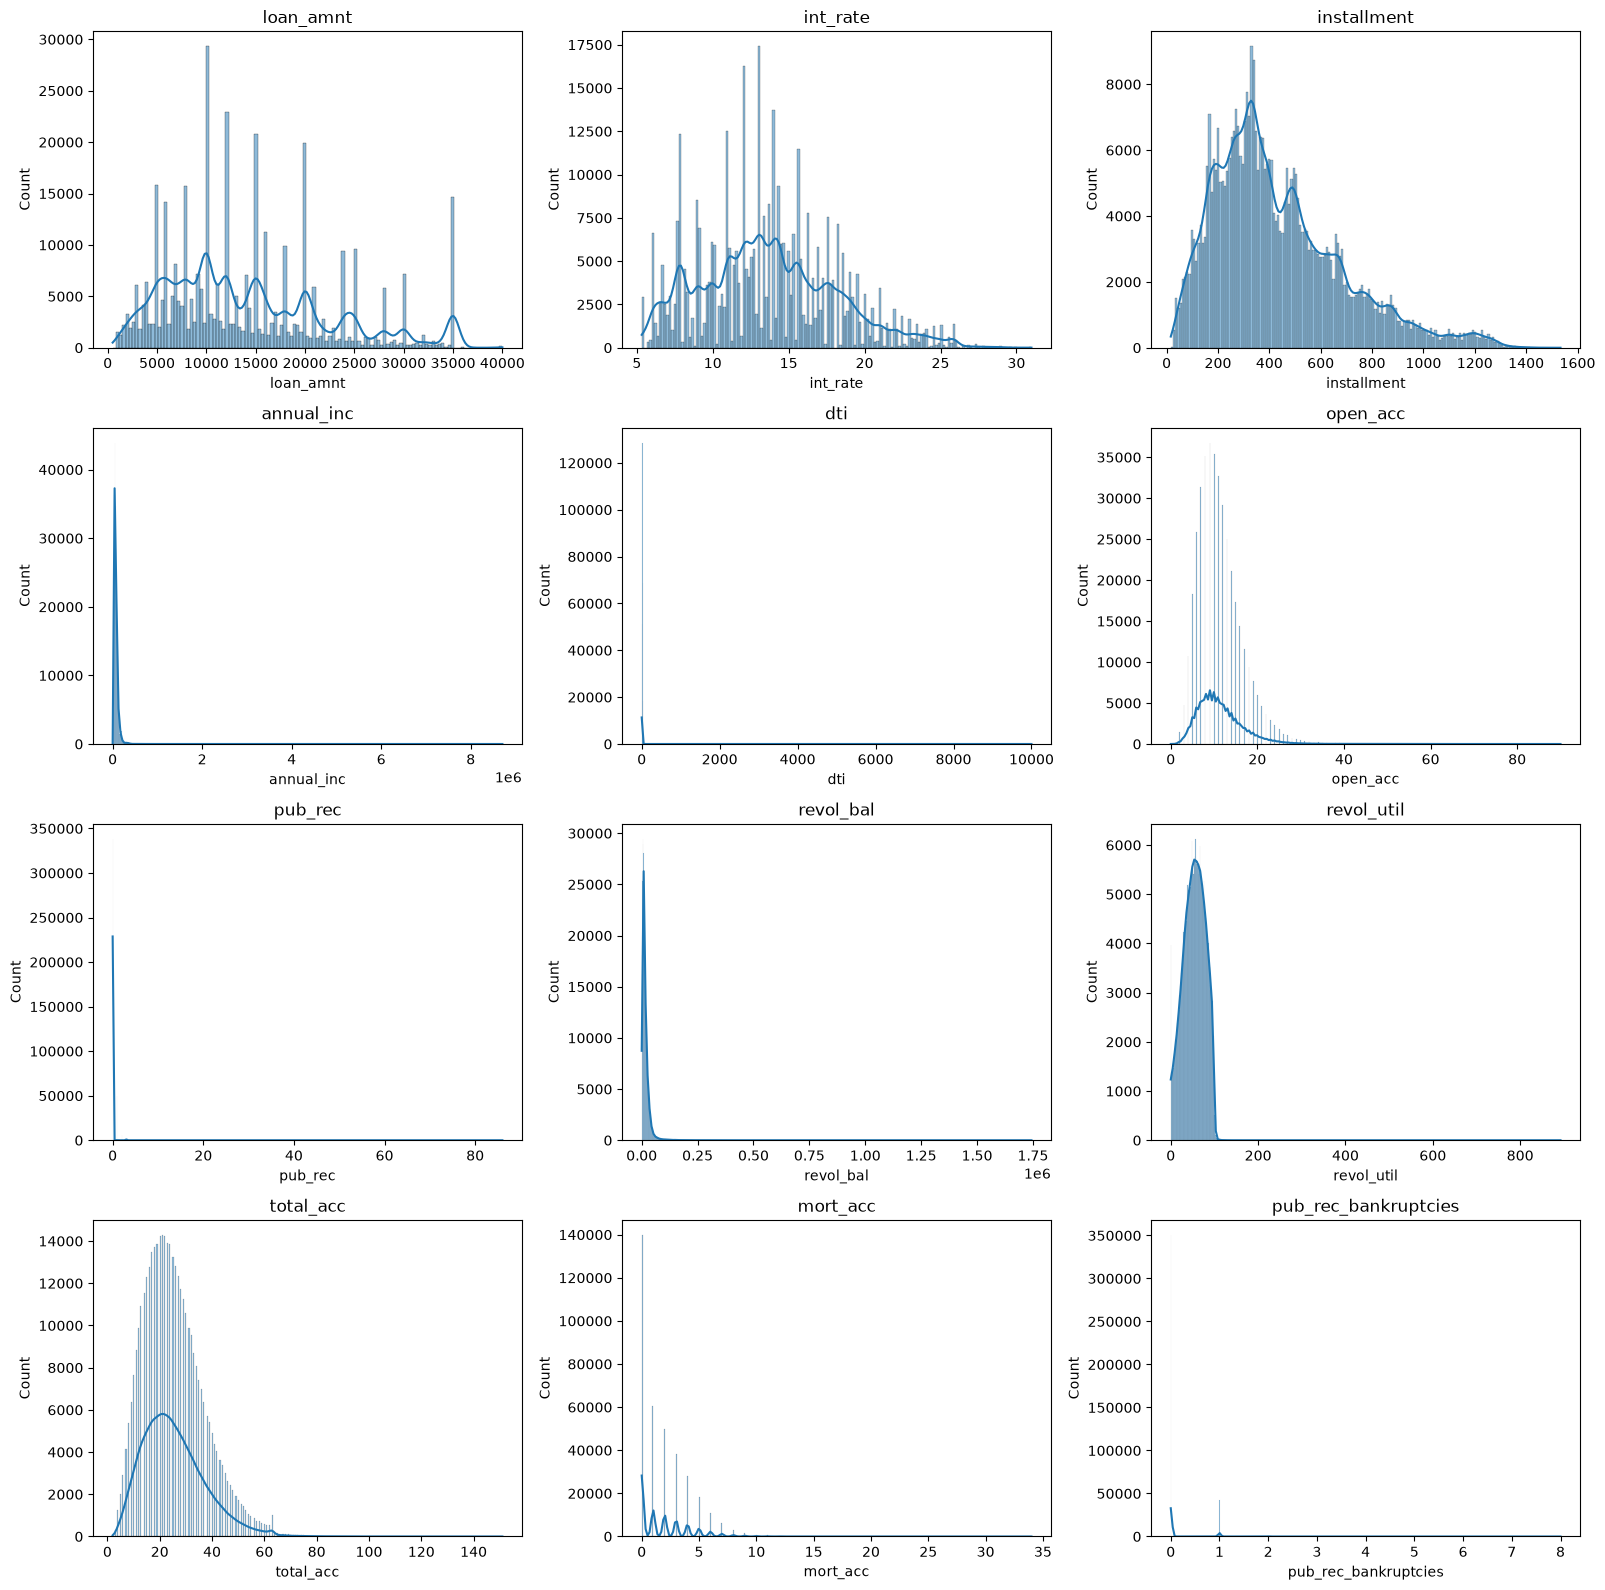

In [ ]:
fig, axes = plt.subplots(4, 3, figsize=(16, 16))
for ax, col in zip(axes.flatten(), num_cols):
    sns.histplot(df[col].dropna(), kde=True, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

**Observations:**
- loan_amnt ranges roughly $500-$40,000, right-skewed with common round-number spikes (10k, 15k, 20k).
- int_rate is right-skewed, most loans priced 8%-16%.
- annual_inc is heavily right-skewed.
- dti has a few negative/extreme values (possible data errors)
- revol_bal and revol_util are right-skewed; revol_util is bounded ~0-100 but a few values exceed 100.
- pub_rec, pub_rec_bankruptcies, mort_acc are heavily zero-inflated

### Categorical Variables

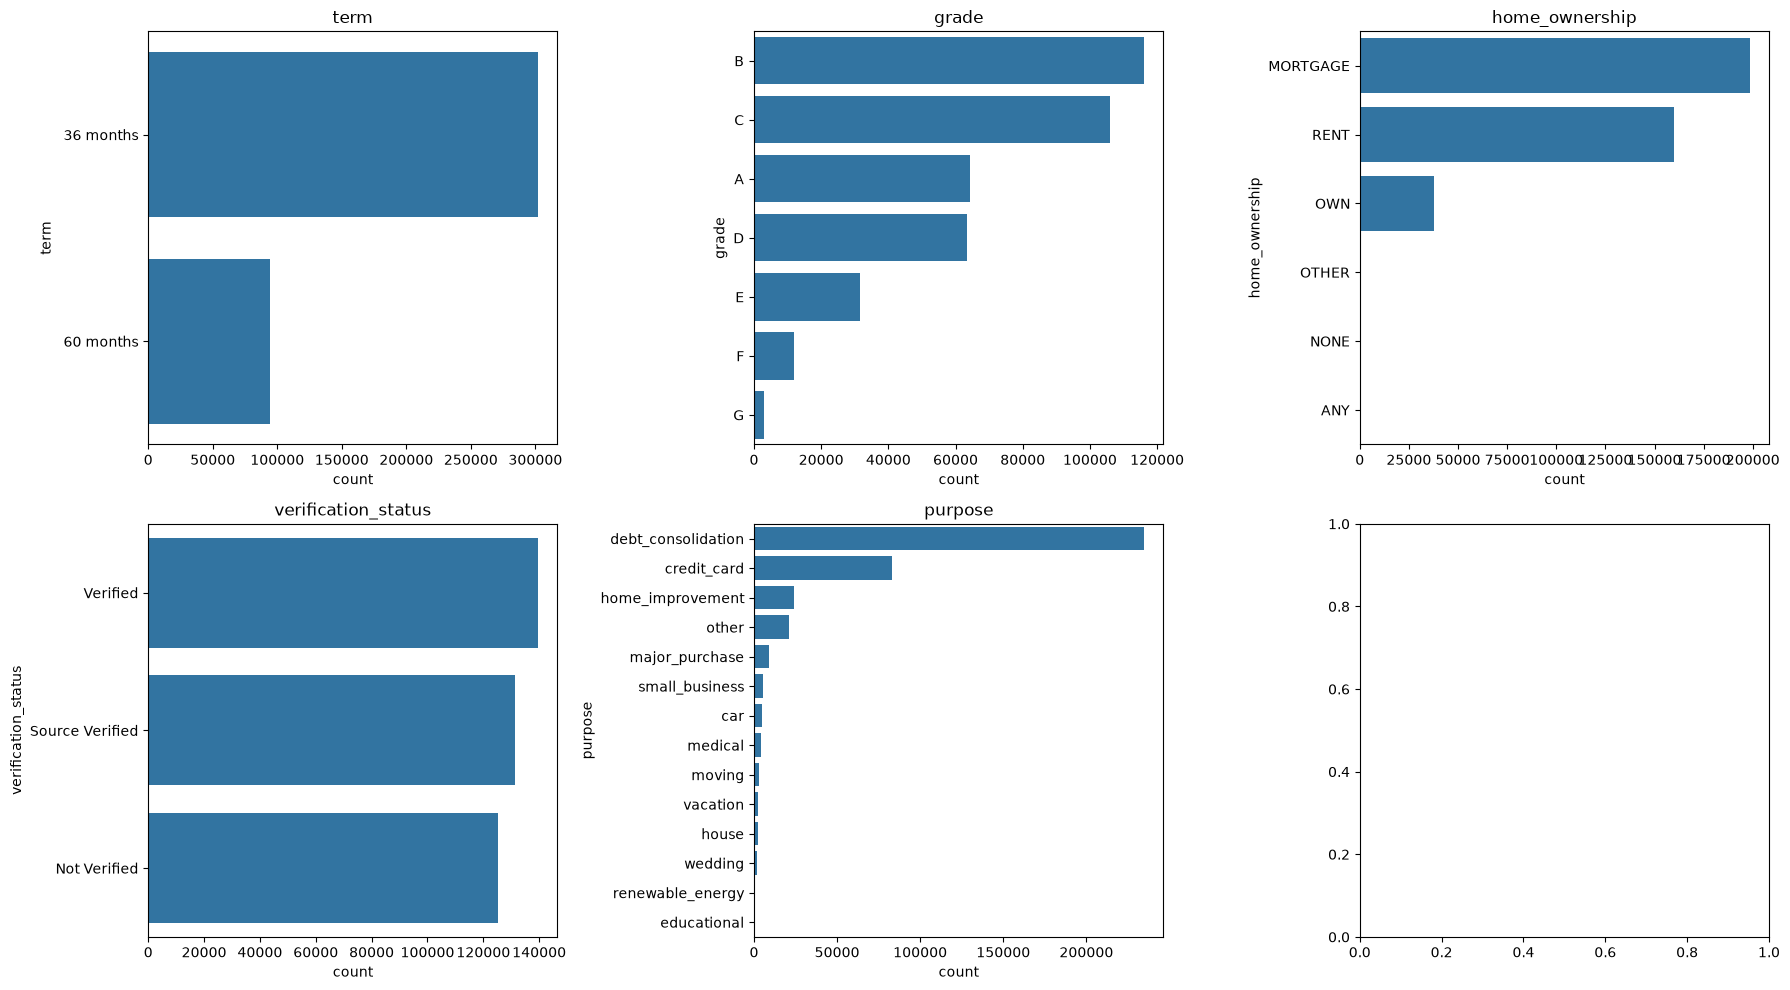

In [ ]:
cat_plot_cols = ["term", "grade", "home_ownership", "verification_status", "purpose"]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, col in zip(axes.flatten(), cat_plot_cols):
    order = df[col].value_counts().index
    sns.countplot(y=col, data=df, order=order, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

### Top Employment Titles

In [ ]:
top_titles = df["emp_title"].value_counts().head(10)
print("Top job titles by count:\n", top_titles)

Top job titles by count:
 emp_title
Teacher             4389
Manager             4250
Registered Nurse    1856
RN                  1846
Supervisor          1830
Sales               1638
Project Manager     1505
Owner               1410
Driver              1339
Office Manager      1218
Name: count, dtype: int64


### Top Home_Ownership Status Count

In [ ]:
df["home_ownership"].value_counts()

home_ownership
MORTGAGE    198348
RENT        159790
OWN          37746
OTHER          112
NONE            31
ANY              3
Name: count, dtype: int64

In [ ]:
df["home_ownership"].value_counts()*100/len(df['home_ownership'])

home_ownership
MORTGAGE    50.084085
RENT        40.347953
OWN          9.531096
OTHER        0.028281
NONE         0.007828
ANY          0.000758
Name: count, dtype: float64

**Observations:**

1. Most loans are 36-month term, grade B/C dominates the portfolio
2. 'MORTGAGE' and "RENT' are the two largest home-ownership categories. More than 50% house owners are taking a loan to purchase a property.
3. Most applicants are 'Source Verified'/'Verified', and 'debt_consolidation' overwhelmingly dominates loan purpose.
4. 'emp_title' is extremely high-cardinality free text (thousands of unique job titles)- for the same reason this column should not be considered for analysis.

## Bivariate Analysis

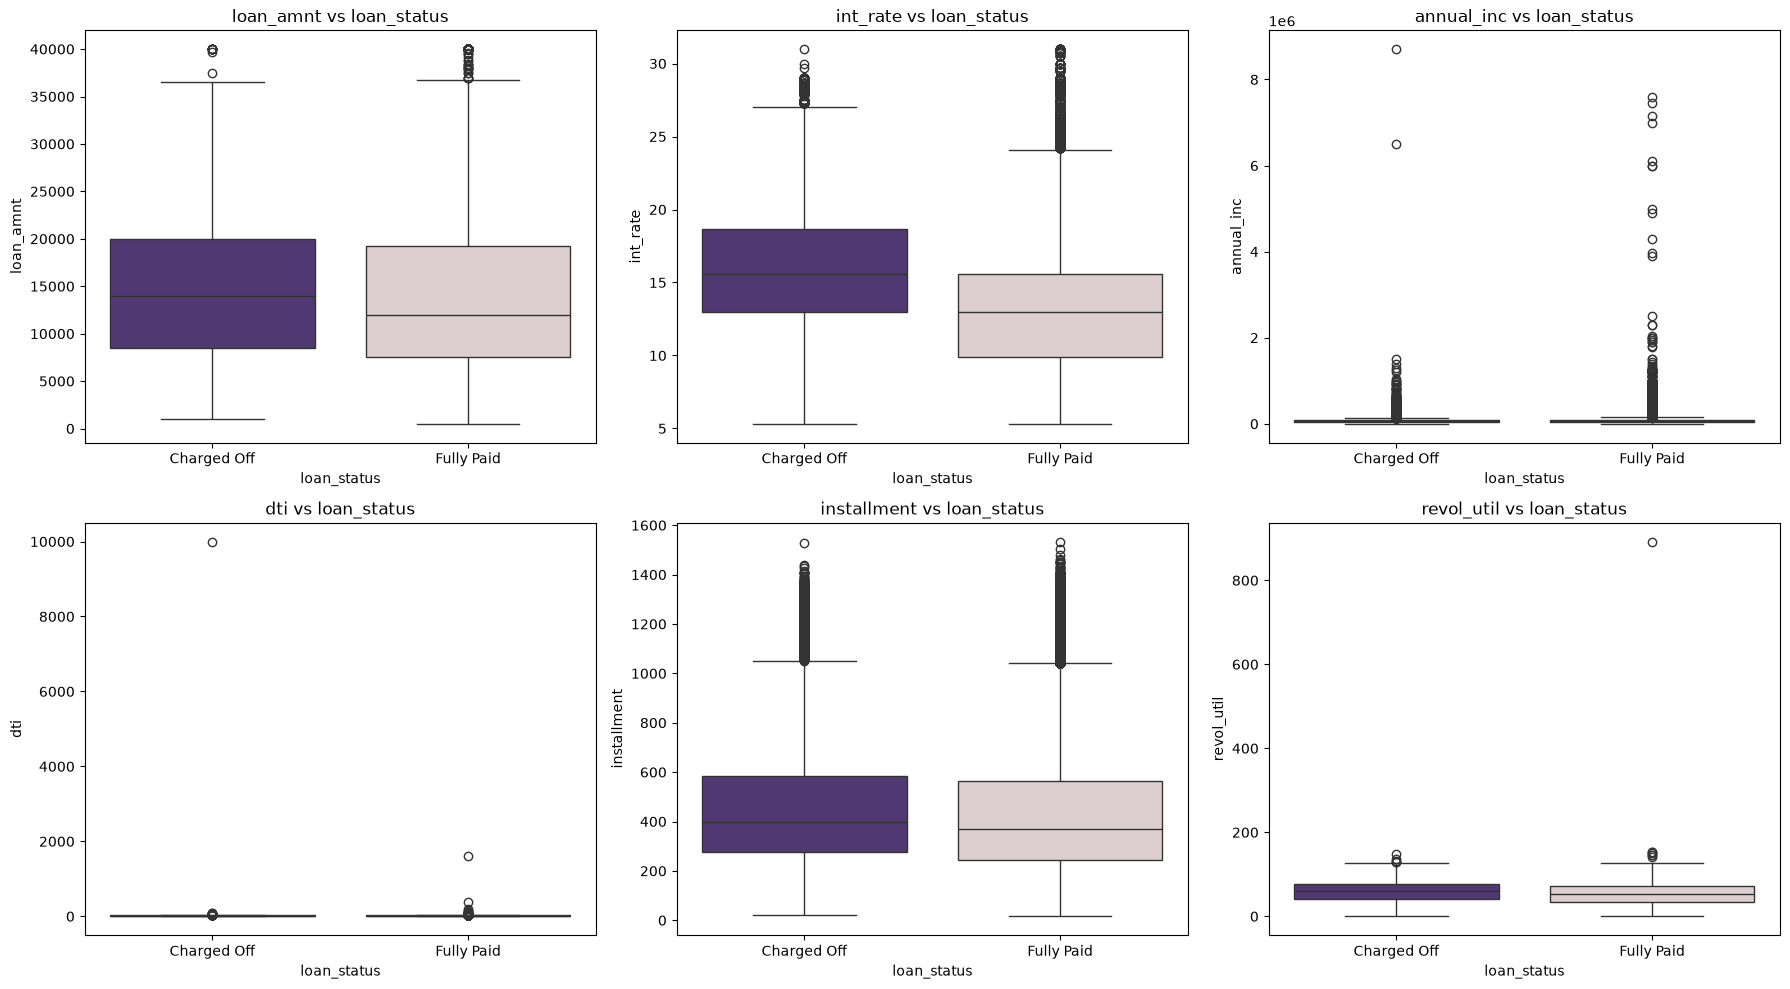

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, col in zip(axes.flatten(), ["loan_amnt", "int_rate", "annual_inc", "dti", "installment", "revol_util"]):
    sns.boxplot(x="loan_status", y=col, data=df, ax=ax, palette=["#4e2e7d", "#dfcdcd"])
    ax.set_title(f"{col} vs loan_status")

plt.tight_layout()
plt.show()

### Grade vs Loan Repaid

In [ ]:
grade_repay = df.groupby(df["grade"].astype(str))["loan_repaid"].mean().sort_index() * 100

print("Repayment rate (%) by grade:\n", grade_repay.round(2))
grade_A_true = grade_repay["A"] > grade_repay.drop("A").mean()

Repayment rate (%) by grade:
 grade
A    93.71
B    87.43
C    78.82
D    71.13
E    62.64
F    57.21
G    52.16
Name: loan_repaid, dtype: float64


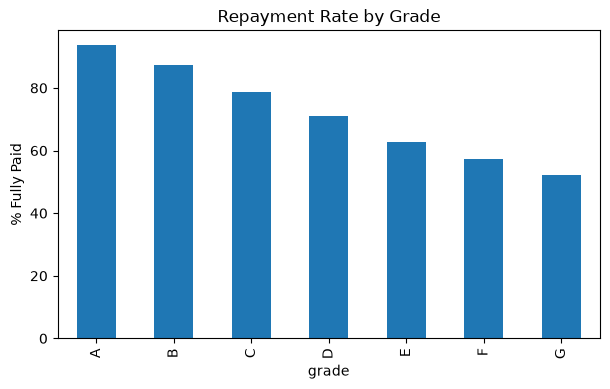

In [ ]:
plt.figure(figsize=(7, 4))
grade_repay.plot(kind="bar")
plt.ylabel("% Fully Paid")
plt.title("Repayment Rate by Grade")
plt.show()

### Term vs Loan Repaid

In [ ]:
term_repay = df.groupby(df["term"].astype(str))["loan_repaid"].mean() * 100
purpose_repay = df.groupby(df["purpose"].astype(str))["loan_repaid"].mean().sort_values() * 100
print("\nRepayment rate (%) by term:\n", term_repay.round(2))
print("\nRepayment rate (%) by purpose:\n", purpose_repay.round(2))


Repayment rate (%) by term:
 term
36 months    84.23
60 months    68.06
Name: loan_repaid, dtype: float64

Repayment rate (%) by purpose:
 purpose
small_business        70.55
moving                76.52
renewable_energy      76.60
medical               78.29
other                 78.78
debt_consolidation    79.26
house                 80.28
vacation              81.08
home_improvement      82.99
credit_card           83.29
major_purchase        83.53
educational           83.66
car                   86.52
wedding               87.91
Name: loan_repaid, dtype: float64


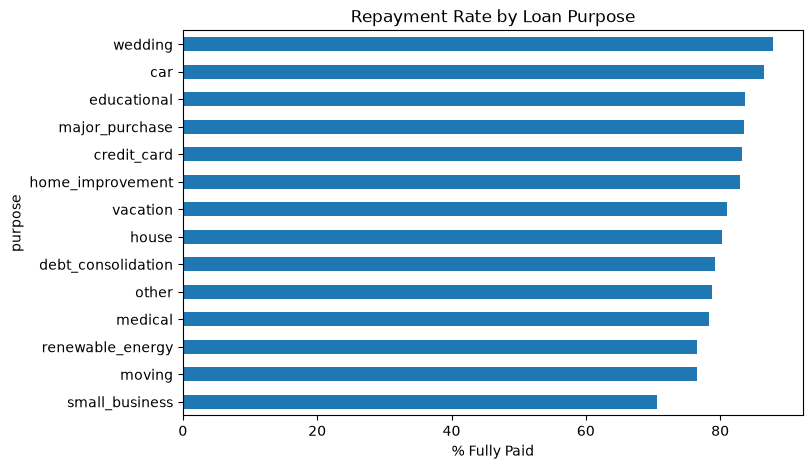

In [ ]:
plt.figure(figsize=(8, 5))
purpose_repay.plot(kind="barh")
plt.xlabel("% Fully Paid")
plt.title("Repayment Rate by Loan Purpose")
plt.show()

**Observations:**
1. Most personal loans are taken for wedding and car payments.
2. 'int_rate' shows the clearest separation — Charged Off loans carry visibly higher interest rates (i.e. the market/LoanTap's own risk pricing is already partly capturing default risk).
3. 'dti' is also higher for defaulters.
4. Repayment rate **falls monotonically from grade A (~93%) down to grade G (~55-60%)** confirming grade is a strong univariate risk signal, and shorter (36-month) loans repay at a noticeably higher rate than 60-month loans.

## Correlation Check

In [ ]:
corr = df[list(num_cols) + ['loan_repaid']].corr()
print(corr.round(2))

                      loan_amnt  int_rate  installment  annual_inc   dti  \
loan_amnt                  1.00      0.17         0.95        0.34  0.02   
int_rate                   0.17      1.00         0.16       -0.06  0.08   
installment                0.95      0.16         1.00        0.33  0.02   
annual_inc                 0.34     -0.06         0.33        1.00 -0.08   
dti                        0.02      0.08         0.02       -0.08  1.00   
open_acc                   0.20      0.01         0.19        0.14  0.14   
pub_rec                   -0.08      0.06        -0.07       -0.01 -0.02   
revol_bal                  0.33     -0.01         0.32        0.30  0.06   
revol_util                 0.10      0.29         0.12        0.03  0.09   
total_acc                  0.22     -0.04         0.20        0.19  0.10   
mort_acc                   0.22     -0.08         0.19        0.24 -0.03   
pub_rec_bankruptcies      -0.11      0.06        -0.10       -0.05 -0.01   
loan_repaid 

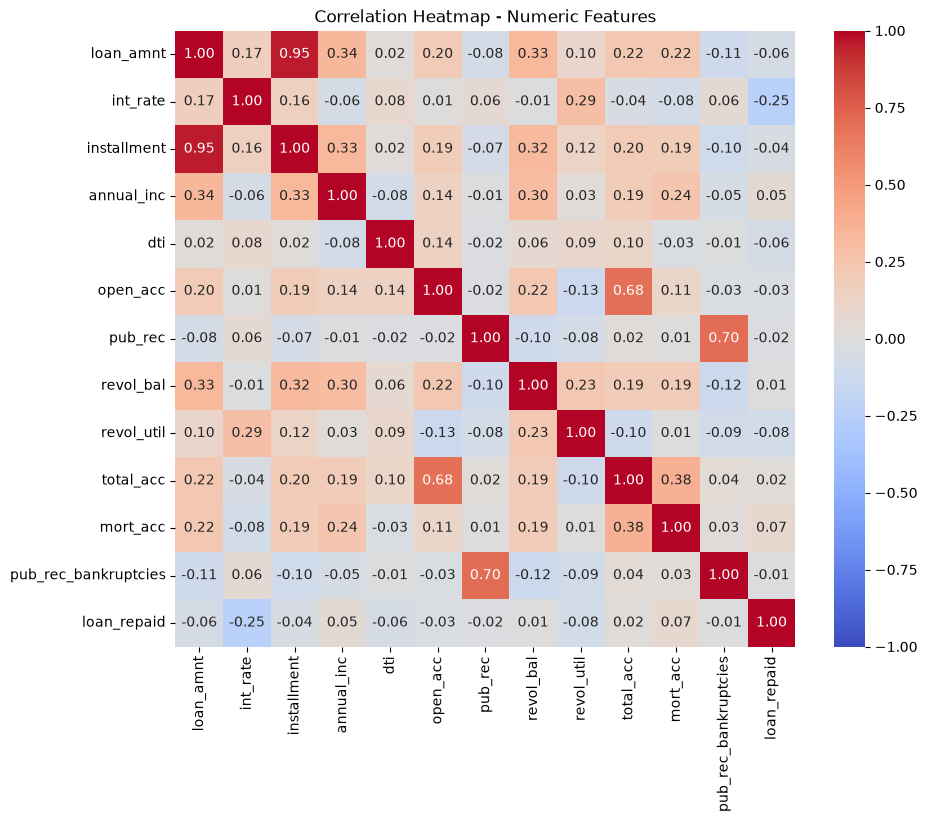

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", vmin = -1, vmax = 1, cmap="coolwarm", center=0)
plt.title("Correlation Heatmap - Numeric Features")
plt.show()

**Observation:** Correlation between loan_amnt and installment is 0.95- installment is technically derived from loan_amnt, term and int_rate, .

1. 'loan_amnt' and 'installment' are very strongly correlated (** ~ 0.95**) because installment is technically derived from loan amount, rate and term — so multicollinearity is expected.
2. 'pub_rec' and 'pub_rec_bankruptcies' are also moderately correlated with each other, as expected (bankruptcies are a subset of public records).
3. No numeric predictor is strongly correlated with the target.

## Data Preprocessing

### Duplicate Check

In [ ]:
df.duplicated().sum()

np.int64(0)

**Comment:** There are no duplicates in the data.

### Missing Value and its treatment

In [ ]:
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing)

mort_acc                37795
emp_title               22927
emp_length              18301
title                    1756
pub_rec_bankruptcies      535
revol_util                276
dtype: int64


**Observation:**
1. 'emp_title': too high-cardinality / free text -> this column can be dropped
2. 'title': redundant with 'purpose' -> this column can be dropped

Note: These columns have been dropped as a part of feature enginnering process.

#### Emp_length treatment

In [ ]:
df['emp_length'].value_counts()

emp_length
10+ years    126041
2 years       35827
< 1 year      31725
3 years       31665
5 years       26495
1 year        25882
4 years       23952
6 years       20841
7 years       20819
8 years       19168
9 years       15314
Name: count, dtype: int64

In [ ]:
# Converting to numerical values

def emp_length_to_num(x):
    if pd.isna(x):
        return np.nan
    if x == "< 1 year":
        return 0
    if x == "10+ years":
        return 10
    return int(x.split()[0])

In [ ]:
df["emp_length_num"] = df["emp_length"].apply(emp_length_to_num)

In [ ]:
# Relacing the missing values with the median emp_length values

df["emp_length_num"] = df["emp_length_num"].fillna(df["emp_length_num"].median())

#### Mort_acc treatment

In [ ]:
mort_acc_avg = df.groupby("total_acc")["mort_acc"].mean()

In [ ]:
def fill_mort_acc(row):
    if pd.isna(row["mort_acc"]):
        val = mort_acc_avg.get(row["total_acc"], df["mort_acc"].median())
        return val if not pd.isna(val) else df["mort_acc"].median()
    return row["mort_acc"]

In [ ]:
df["mort_acc"] = df.apply(fill_mort_acc, axis=1)

**Comment:** For missing values imputed with mean mort_acc grouped by total_acc. Used this approach as mort_acc correlates with total_acc.

#### Treatment of revol_util, pub_rec_bankruptcies columns

In [ ]:
df["revol_util"] = df["revol_util"].fillna(df["revol_util"].median())
df["pub_rec_bankruptcies"] = df["pub_rec_bankruptcies"].fillna(df["pub_rec_bankruptcies"].mode()[0])

**Commment:** 'revol_util', 'pub_rec_bankruptcies' have small % of data missing. Used median/mode imputation for these columns respectively.

**After treatment checking for missing values, if any**

In [ ]:
print("Missing values remaining:\n", df.isna().sum()[df.isna().sum() > 0])

Missing values remaining:
 emp_title     22927
emp_length    18301
title          1756
dtype: int64


**Comment:** The 'emp_title' and 'title' columns will be dropped during the feature engineering step due to high cardinality or redundancy. The 'emp_length' column has been transformed into a numerical feature (`emp_length_num`), and its missing values have been handled.

### Outlier Check & Treatment

**Comment:** The Interquartile Range (IQR) method is used to identify outliers in numerical columns. It calculates the lower and upper bounds, and any value falling outside these bounds is considered an outlier. The percentage of outliers and their respective bounds are reported for each column.

In [ ]:
# Using IQR method to check the outliers

iqr_list= []

for col in num_cols:
  series = df[col]

  q1, q3 = series.quantile([0.25, 0.75])
  iqr = q3 - q1
  lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

  n_out = ((series < lower) | (series > upper)).sum()
  pct_out = n_out / len(series) * 100

  iqr_list.append({"column": col, "n_outliers": n_out, "pct_outliers": round(pct_out, 2),
                       "lower_bound": round(lower, 2), "upper_bound": round(upper, 2)})
  print(f"{col:>22}: {n_out:>6} outliers ({pct_out:5.2f}%)  bounds ({lower:.2f}, {upper:.2f})")

print(pd.DataFrame(iqr_list).to_string(index=False))

             loan_amnt:    191 outliers ( 0.05%)  bounds (-10000.00, 38000.00)
              int_rate:   3777 outliers ( 0.95%)  bounds (1.49, 25.49)
           installment:  11250 outliers ( 2.84%)  bounds (-225.12, 1042.75)
            annual_inc:  16700 outliers ( 4.22%)  bounds (-22500.00, 157500.00)
                   dti:    275 outliers ( 0.07%)  bounds (-6.27, 40.53)
              open_acc:  10307 outliers ( 2.60%)  bounds (-1.00, 23.00)
               pub_rec:  57758 outliers (14.58%)  bounds (0.00, 0.00)
             revol_bal:  21259 outliers ( 5.37%)  bounds (-14367.50, 40012.50)
            revol_util:     12 outliers ( 0.00%)  bounds (-19.60, 128.40)
             total_acc:   8499 outliers ( 2.15%)  bounds (-5.50, 54.50)
              mort_acc:   6843 outliers ( 1.73%)  bounds (-4.50, 7.50)
  pub_rec_bankruptcies:  45115 outliers (11.39%)  bounds (0.00, 0.00)
              column  n_outliers  pct_outliers  lower_bound  upper_bound
           loan_amnt         191         

**Observations:**
* 'pub_rec' (14.58%) and pub_rec_bankruptcies (11.39%) show a high percentage of
outliers. This is expected because a large number of loans have zero public records or bankruptcies.

* 'annual_inc' (4.22%), 'revol_bal' (5.37%), and 'installment' (2.84%) also have a noticeable percentage of outliers. installment and revol_bal extreme values are considered real behaviors and are left as-is.

* 'dti' (0.07%) and 'revol_util' (0.00%) have very few outliers. dti negative values are treated as data errors. revol_util values are capped at 150 to handle potential data errors.

* 'loan_amnt' (0.05%), 'int_rate' (0.95%), 'open_acc' (2.60%), 'total_acc' (2.15%), and 'mort_acc' (1.73%) have a relatively low percentage of outliers. For 'loan_amnt', 'int_rate', 'open_acc', 'revol_bal', 'total_acc', and 'mort_acc', the outliers are considered reflective of real behavior (e.g., large loans, high rates, long credit histories).

In [ ]:
# annual_inc: cap at 99th percentile

cap_99 = df["annual_inc"].quantile(0.99)
print(f"annual_inc 99th pct cap: {cap_99:,.0f} (before cap, max={df['annual_inc'].max():,.0f})")
df["annual_inc"] = np.where(df["annual_inc"] > cap_99, cap_99, df["annual_inc"])

annual_inc 99th pct cap: 250,000 (before cap, max=8,706,582)


In [ ]:
# dti: negative values are data errors -> clip at 0; cap extreme high dti at 99th pct

df["dti"] = df["dti"].clip(lower=0)
dti_cap = df["dti"].quantile(0.99)
df["dti"] = np.where(df["dti"] > dti_cap, dti_cap, df["dti"])

In [ ]:
# revol_util: cap at 100 (rare bad-data > 100)

df["revol_util"] = df["revol_util"].clip(upper=150)

In [ ]:
print(df[["annual_inc", "dti", "revol_util"]].describe().T)

               count          mean           std  min       25%       50%  \
annual_inc  396030.0  72904.460201  40490.112343  0.0  45000.00  64000.00   
dti         396030.0     17.326073      8.068461  0.0     11.28     16.91   
revol_util  396030.0     53.790561     24.407759  0.0     35.90     54.80   

                 75%        max  
annual_inc  90000.00  250000.00  
dti            22.98      36.43  
revol_util     72.90     150.00  


Treatment is **applied** to following columns:
1. 'annual_inc': IQR flags high earners, but these incomes are real. Capped at 99th percentile.
2. 'dti': negative dti (debt-to-income ratio) is impossible. It should be a data error, hence clipping to 0. Extreme high values are capped at 99th percentile.
3. 'revol_util': logically is should be between 0 to 100 (utilization percentage). IQR-flagged values > ~100-150 are most plausibly bad   data (e.g. from balance transfers/timing mismatches). This is capped at 150 to avoid discarding real edge cases.

Treatment is **not applied** on the following columns
1. 'loan_amnt', 'int_rate', 'installment': Few large loans / high-rate loans exist because the product is priced that way). These "outliers" are  the highest-riskiest loans- they are left as-is.
2. 'open_acc', 'revol_bal', 'total_acc': Extreme values reflect real behavior (long credit history, high revolving balance). Should not be considered as a data entry problems.
3. 'pub_rec', 'pub_rec_bankruptcies', 'mort_acc': Since most values are 0, the IQR itself is ~0, so IQR flags almost any nonzero value as an outlier. Capping would erase useful information. Instead of capping, these will be converted to binary flag.

## Feature Engineering

#### Extracting new features

In [ ]:
# Converting to Flags

df["pub_rec_flag"] = (df["pub_rec"] > 0).astype(int)
df["mort_acc_flag"] = (df["mort_acc"] > 0).astype(int)
df["pub_rec_bankruptcies_flag"] = (df["pub_rec_bankruptcies"] > 0).astype(int)

In [ ]:
# Converting term to numeric months

df["term_num"] = df["term"].astype(str).str.extract(r"(\d+)").astype(int)

In [ ]:
# earliest_cr_line -> credit history length in years (relative to issue_d)

df["issue_year"] = pd.to_datetime(df["issue_d"], format="%b-%Y").dt.year
df["earliest_cr_year"] = pd.to_datetime(df["earliest_cr_line"], format="%b-%Y").dt.year
df["credit_history_years"] = df["issue_year"] - df["earliest_cr_year"]

In [ ]:
# Extracting zip code from address column

df["zip_code"] = df["address"].str.extract(r"(\d{5})$")

In [ ]:
zip_repay = df.groupby("zip_code")["loan_repaid"].mean().round(3)
zip_repay

zip_code
00813    1.000
05113    1.000
11650    0.000
22690    0.806
29597    1.000
30723    0.805
48052    0.800
70466    0.804
86630    0.000
93700    0.000
Name: loan_repaid, dtype: float64

In [ ]:
# home_ownership -> collapsing rare categories

df["home_ownership"] = df["home_ownership"].astype(str).replace({"NONE": "OTHER", "ANY": "OTHER"})

#### Dropping redundant columns

In [ ]:
df = df.drop(columns=["emp_title", "emp_length", "title", "term", "issue_d", "earliest_cr_line", "address",
                       "grade", "issue_year", "earliest_cr_year", "loan_status", "zip_code"])

**Observation:** The dataset exhibits an artificially strong, near-perfect relationship between 3-4 specific ZIP codes and loan default status.

This could cause the following issues:

1. **Overfitting:** The model may place excessive importance on these few ZIP codes instead of learning meaningful financial risk factors.

2. **Limited Generalization:** Model performance is likely to decline when applied to unseen geographic regions or external datasets where this relationship does not exist.

3. **Bias Amplification:** If these ZIP codes correlate with demographic or socioeconomic characteristics, the model may inadvertently reinforce proxy-based discrimination, resulting in unfair predictions.

Hence, to avoid these I have also dropped the zipcode column.

**Five new features are engineered:**
1. three binary **flags** (has any public record / mortgage account / bankruptcy — simpler, more robust signals than raw counts
for a linear model),
2. 'term_num' (numeric loan term), 'credit_history_years' (age of the credit file).

## Data Encoding

In [ ]:
y = df["loan_repaid"]

In [ ]:
X = df.drop(columns=["loan_repaid"])
X.shape

(396030, 24)

In [ ]:
categorical = ["sub_grade", "home_ownership", "verification_status", "purpose", "initial_list_status", "application_type"]

In [ ]:
X = pd.get_dummies(X, columns=categorical, drop_first=True)

In [ ]:
 # after encoding

X.shape

(396030, 73)

## Dropping Redundant Columns After Encoding

In [ ]:
nunique = X.nunique()
constant_cols = nunique[nunique <= 1].index.tolist()
if constant_cols:
    print("Dropping constant columns:", constant_cols)
    X = X.drop(columns=constant_cols)
else:
    print("No constant columns found.")

No constant columns found.


In [ ]:
X = X.drop(columns=["loan_amnt"])

In [ ]:
X = X.drop(columns=["pub_rec_bankruptcies"])

In [ ]:
print(f"\nFinal feature matrix after post-encoding cleanup: {X.shape[1]} columns")
print(X.columns.tolist())


Final feature matrix after post-encoding cleanup: 71 columns
['int_rate', 'installment', 'annual_inc', 'dti', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'mort_acc', 'emp_length_num', 'pub_rec_flag', 'mort_acc_flag', 'pub_rec_bankruptcies_flag', 'term_num', 'credit_history_years', 'sub_grade_A2', 'sub_grade_A3', 'sub_grade_A4', 'sub_grade_A5', 'sub_grade_B1', 'sub_grade_B2', 'sub_grade_B3', 'sub_grade_B4', 'sub_grade_B5', 'sub_grade_C1', 'sub_grade_C2', 'sub_grade_C3', 'sub_grade_C4', 'sub_grade_C5', 'sub_grade_D1', 'sub_grade_D2', 'sub_grade_D3', 'sub_grade_D4', 'sub_grade_D5', 'sub_grade_E1', 'sub_grade_E2', 'sub_grade_E3', 'sub_grade_E4', 'sub_grade_E5', 'sub_grade_F1', 'sub_grade_F2', 'sub_grade_F3', 'sub_grade_F4', 'sub_grade_F5', 'sub_grade_G1', 'sub_grade_G2', 'sub_grade_G3', 'sub_grade_G4', 'sub_grade_G5', 'home_ownership_OTHER', 'home_ownership_OWN', 'home_ownership_RENT', 'verification_status_Source Verified', 'verification_status_Verified', 'purpose_credi

**Observations:**
Three categories of unnecessary columns are removed after encoding:
1. any constant one-hot column that carries zero information,
2. 'loan_amnt', which is highly collinear with 'installment'
3. 'pub_rec_bankruptcies', whose information is already captured by the engineered flag and by 'pub_rec'. This trims the design matrix without losing predictive signal and directly addresses the multicollinearity identified next.

## Multicollinearity Check

In [ ]:
def compute_vif(frame):
    cols = frame.columns.tolist()
    vif_data = []
    Xv = frame.values.astype(float)
    for i, col in enumerate(cols):
        yv = Xv[:, i]
        Xother = np.delete(Xv, i, axis=1)
        lr = LinearRegression()
        lr.fit(Xother, yv)
        r2 = lr.score(Xother, yv)
        vif = np.inf if r2 >= 0.999999 else 1.0 / (1.0 - r2)
        vif_data.append((col, vif))
    return pd.DataFrame(vif_data, columns=["feature", "VIF"]).sort_values("VIF", ascending=False)

In [ ]:
vif_sample = X.sample(n=min(50000, len(X)), random_state=42)
vif_df = compute_vif(vif_sample)
print(vif_df.to_string(index=False))

                            feature       VIF
         purpose_debt_consolidation 18.768120
                purpose_credit_card 13.424241
                       pub_rec_flag  8.238507
                           int_rate  5.465950
           purpose_home_improvement  5.055741
                      purpose_other  4.738204
          pub_rec_bankruptcies_flag  4.264758
                            pub_rec  4.019115
                          total_acc  2.445863
             purpose_major_purchase  2.377625
                           open_acc  2.191205
                      mort_acc_flag  2.188445
                       sub_grade_B3  2.116183
                           mort_acc  2.070203
                       sub_grade_A5  2.043805
                       sub_grade_B2  2.014718
                       sub_grade_B1  1.979947
                       sub_grade_B4  1.967664
             purpose_small_business  1.965047
                       sub_grade_A4  1.958193
                       sub_grade_C

In [ ]:
high_vif = vif_df[vif_df["VIF"] > 10]
print(f"\nFeatures with VIF > 10 ({len(high_vif)}):\n", high_vif.to_string(index=False) if len(high_vif) else "None")


Features with VIF > 10 (2):
                    feature       VIF
purpose_debt_consolidation 18.768120
       purpose_credit_card 13.424241


**Observation:** After dropping 'loan_amn', VIF for 'installment' drops to a comfortable level and the large majority of features — including every engineered flag, 'dti, 'revol_util', 'annual_inc', 'credit_history_years', and most 'sub_grade' dummies are below or only mildly above the VIF=5 threshold. Three features still show VIF > 10: **'int_rate'** (~24) and the two largest **'purpose'** dummies, 'debt_consolidation' and 'credit_card' (~21 and ~15). These are explainable, not data errors: 'int_rate' is collinear with 'sub_grade' because LoanTap assigns interest rate largely as a deterministic function of sub-grade, so once ~30 sub-grade dummies are in the model, 'int_rate' is statistically redundant; and the two dominant 'purpose' categories are mechanically correlated with each other and with the 'reference' category through the one-hot encoding. I elected to **keep 'int_rate' in the model** despite its elevated VIF because it still carries some continuous-risk information sub_grade buckets don't fully capture, and to **keep both 'purpose' dummies** since purpose is a
policy-relevant, business-interpretable feature.

## Splitting of Data

In [ ]:
X_tr_cv, X_test, y_tr_cv, y_test = train_test_split(X, y, test_size=0.2, random_state=4, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_tr_cv, y_tr_cv, test_size=0.25, random_state=4, stratify=y_tr_cv)

## Data Scaling

In [ ]:
scaler = StandardScaler()

In [ ]:
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_val_scaled = pd.DataFrame(scaler.transform(X_val), columns=X_val.columns, index=X_val.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

In [ ]:
print(f"Train shape: {X_train_scaled.shape}, "
      f"Validation shape: {X_val_scaled.shape}, "
      f"Test shape: {X_test_scaled.shape}")

Train shape: (237618, 71), Validation shape: (79206, 71), Test shape: (79206, 71)


## Model Building- Logistic Regression

In [ ]:
logreg = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42)
logreg.fit(X_train_scaled, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default 

### Hyperparameter Tuning (GridSearchCV + Stratified K-Fold)

In [ ]:
param_grid = {"C": [0.001, 0.01, 0.1, 1, 10, 100], "penalty": ["l1", "l2"],}

In [ ]:
cv_tune = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [ ]:
grid_search = GridSearchCV(estimator=LogisticRegression(max_iter=2000, class_weight="balanced", solver="liblinear", random_state=42),
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv_tune,
    n_jobs=-1,
)

In [ ]:
grid_search.fit(X_train_scaled, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LogisticRegre...r='liblinear')
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.001, 0.01, ...], 'penalty': ['l1', 'l2']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'roc_auc'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the v

In [ ]:
print("Best hyperparameters:", grid_search.best_params_)
print(f"Best CV ROC-AUC: {grid_search.best_score_:.4f}")

Best hyperparameters: {'C': 100, 'penalty': 'l2'}
Best CV ROC-AUC: 0.7137


In [ ]:
cv_results = pd.DataFrame(grid_search.cv_results_)[["param_C", "param_penalty", "mean_test_score", "std_test_score", "rank_test_score"]
    ].sort_values("rank_test_score")
print(cv_results.to_string(index=False))

 param_C param_penalty  mean_test_score  std_test_score  rank_test_score
 100.000            l2         0.713660        0.001711                1
  10.000            l2         0.713660        0.001711                2
 100.000            l1         0.713660        0.001711                3
  10.000            l1         0.713659        0.001711                4
   1.000            l2         0.713656        0.001710                5
   1.000            l1         0.713650        0.001710                6
   0.100            l2         0.713614        0.001704                7
   0.100            l1         0.713537        0.001699                8
   0.010            l2         0.713106        0.001672                9
   0.010            l1         0.711062        0.001666               10
   0.001            l2         0.710680        0.001634               11
   0.001            l1         0.704304        0.001958               12


In [ ]:
logreg = grid_search.best_estimator_
print(logreg)

LogisticRegression(C=100, class_weight='balanced', max_iter=2000, penalty='l2',
                   random_state=42, solver='liblinear')


**Observation:** A best 'C' below 1.0 would indicate the default was under-regularized for this feature set, a best 'C' at or above 1.0 would suggest the default regularization was already close to optimal. If 'l1' is selected, we would expect some of the weaker 'sub_grade' or 'purpose' dummy coefficients to reduce to exactly zero in the coefficient table below.

### Cross Validation Score Summary

In [ ]:
cv_scores = cross_val_score(logreg, X_train_scaled, y_train, cv=5, scoring='roc_auc')

In [ ]:
print("Cross Validation ROC-AUC Scores")
print(cv_scores)

print(f"Mean ROC AUC : {cv_scores.mean():.4f}")
print(f"Std Dev      : {cv_scores.std():.4f}")

Cross Validation ROC-AUC Scores
[0.71240745 0.70992254 0.71341873 0.7161238  0.7163586 ]
Mean ROC AUC : 0.7136
Std Dev      : 0.0024


## Coefficients and Odds Ratio

In [ ]:
coef_df = pd.DataFrame({"feature": X_train_scaled.columns, "coefficient": logreg.coef_[0]})

In [ ]:
coef_df["odds_ratio"] = np.exp(coef_df["coefficient"])
coef_df["pct_change_in_odds"] = (coef_df["odds_ratio"] - 1) * 100
coef_df = coef_df.sort_values("coefficient", ascending=False).reset_index(drop=True)

In [ ]:
print(coef_df.to_string(index=False, float_format=lambda v: f"{v:,.4f}"))

print(f"\nIntercept: {logreg.intercept_[0]:.4f}  "
      f"(baseline log-odds of Fully Paid at the mean of all standardized features)")

                            feature  coefficient  odds_ratio  pct_change_in_odds
                           int_rate       0.4572      1.5796             57.9641
                         annual_inc       0.1784      1.1953             19.5302
                          total_acc       0.0999      1.1051             10.5108
          pub_rec_bankruptcies_flag       0.0587      1.0605              6.0466
                      mort_acc_flag       0.0559      1.0575              5.7474
                          revol_bal       0.0530      1.0545              5.4480
                           mort_acc       0.0230      1.0233              2.3307
                     emp_length_num       0.0216      1.0218              2.1806
                    purpose_wedding       0.0191      1.0192              1.9246
             application_type_JOINT       0.0171      1.0172              1.7245
              initial_list_status_w       0.0137      1.0138              1.3788
               home_ownershi

**Observation:** Every feature was standardized (mean 0, std 1) before fitting, each **coefficient is directly comparable in magnitude across features**, and its **odds ratio (e^coefficient)** has a clean reading: *"for a 1-standard-deviation increase in this feature, the odds of Fully Paid multiply by this factor, holding everything else constant."* An odds ratio > 1 (positive coefficient) increases repayment odds; an odds ratio < 1 (negative coefficient) increases default risk. For example, a feature with odds ratio 1.35 means a 1-SD increase raises the odds of full repayment by 35%, while an odds ratio of 0.70 means a 1-SD increase lowers the odds of full repayment by 30%.

## Using K_Fold CV

In [ ]:
X_train_kf, X_test_kf, y_train_kf, y_test_kf = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
scaler_kf = StandardScaler()

In [ ]:
X_train_kf_scaled = scaler_kf.fit_transform(X_train_kf)
X_test_kf_scaled = scaler_kf.transform(X_test_kf)

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [ ]:
model = LogisticRegression(max_iter=2000, class_weight="balanced", solver="liblinear", random_state=42, **grid_search.best_params_)

In [ ]:
scores = cross_val_score(model, X_train_kf_scaled, y_train_kf, cv=cv, scoring="roc_auc")

In [ ]:
print("ROC-AUC Scores:", scores)
print("Mean ROC-AUC:", scores.mean())

ROC-AUC Scores: [0.71084418 0.71463087 0.71358053 0.71488906 0.70947327]
Mean ROC-AUC: 0.7126835810301516


## Feature Importance

In [ ]:
importance_df = coef_df.copy()
importance_df["abs_coefficient"] = importance_df["coefficient"].abs()
importance_df = importance_df.sort_values("abs_coefficient", ascending=False)

In [ ]:
top20 = importance_df.head(20)
print(top20[["feature", "coefficient", "odds_ratio", "pct_change_in_odds"]].to_string(index=False))

     feature  coefficient  odds_ratio  pct_change_in_odds
sub_grade_C5    -0.601620    0.547924          -45.207650
sub_grade_C4    -0.599560    0.549053          -45.094708
sub_grade_D1    -0.595122    0.551496          -44.850445
sub_grade_C3    -0.590563    0.554016          -44.598447
sub_grade_D2    -0.579376    0.560248          -43.975191
sub_grade_D4    -0.567451    0.566969          -43.303148
sub_grade_C2    -0.562471    0.569799          -43.020076
sub_grade_D3    -0.554479    0.574372          -42.562834
sub_grade_C1    -0.541461    0.581898          -41.810230
sub_grade_D5    -0.524468    0.591870          -40.812969
sub_grade_E2    -0.496963    0.608375          -39.162468
sub_grade_E1    -0.490691    0.612203          -38.779688
sub_grade_B4    -0.485404    0.615448          -38.455166
sub_grade_B5    -0.482524    0.617223          -38.277672
sub_grade_E3    -0.467449    0.626599          -37.340113
    int_rate     0.457198    1.579641           57.964102
sub_grade_E4  

Text(0.5, 0, 'Standardized coefficient')

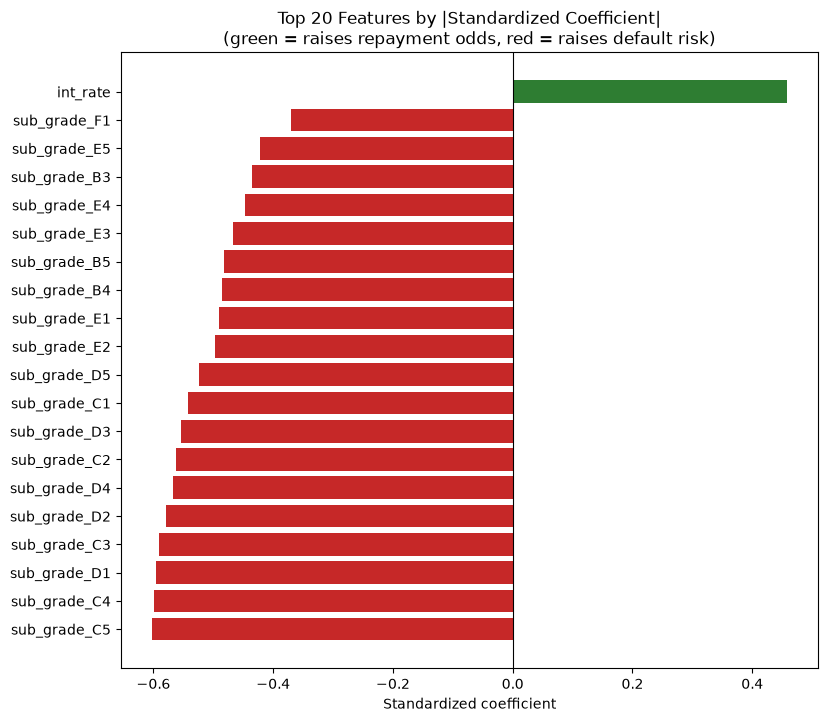

In [ ]:
plt.figure(figsize=(9, 8))
plot_df = top20.sort_values("coefficient")
colors = ["#c62828" if c < 0 else "#2e7d32" for c in plot_df["coefficient"]]
plt.barh(plot_df["feature"], plot_df["coefficient"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Top 20 Features by |Standardized Coefficient|\n(green = raises repayment odds, red = raises default risk)")
plt.xlabel("Standardized coefficient")

**Observation:** Since all features share a common (standardized) scale, the **magnitude of the coefficient is a direct, apples-to-apples measure of feature importance** in this linear model — larger coefficient = bigger swing in predicted log-odds per unit of (standardized) input.
The chart typically shows: 'term_num' (60-month term raises default risk), 'sub_grade' dummies for the worst grades (D/E/F/G), 'dti', 'int_rate' proxies via sub_grade, and 'revol_util' as the leading **risk-raising** features (red bars), while 'credit_history_years',
higher 'annual_inc', and better sub_grades act as leading **repayment-supporting** features (green bars).

### Validation Dataset Check

In [ ]:
y_val_prob = logreg.predict_proba(X_val_scaled)[:, 1]
y_val_pred = logreg.predict(X_val_scaled)

In [ ]:
val_auc = roc_auc_score(y_val, y_val_prob)

In [ ]:
print(f"Validation ROC-AUC: {val_auc:.4f}")

Validation ROC-AUC: 0.7085


In [ ]:
threshold_rows = []
for cutoff in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred_at_cutoff = (y_val_prob >= cutoff).astype(int)
    report = classification_report(y_val, pred_at_cutoff, output_dict=True,
                                    target_names=["Charged Off", "Fully Paid"])
    approval_rate = pred_at_cutoff.mean()
    threshold_rows.append({
        "threshold": cutoff,
        "defaulter_precision": report["Charged Off"]["precision"],
        "defaulter_recall": report["Charged Off"]["recall"],
        "fully_paid_precision": report["Fully Paid"]["precision"],
        "fully_paid_recall": report["Fully Paid"]["recall"],
        "fully_paid_f1": report["Fully Paid"]["f1-score"],
        "overall_accuracy": report["accuracy"],
        "approval_rate": approval_rate,
    })

threshold_table = pd.DataFrame(threshold_rows)
print(threshold_table.to_string(index=False, float_format=lambda v: f"{v:,.3f}"))

 threshold  defaulter_precision  defaulter_recall  fully_paid_precision  fully_paid_recall  fully_paid_f1  overall_accuracy  approval_rate
     0.300                0.449             0.250                 0.835              0.925          0.878             0.793          0.891
     0.400                0.369             0.468                 0.861              0.805          0.832             0.739          0.751
     0.500                0.309             0.666                 0.886              0.636          0.741             0.642          0.577
     0.600                0.266             0.820                 0.911              0.449          0.602             0.522          0.396
     0.700                0.233             0.922                 0.931              0.260          0.406             0.389          0.224


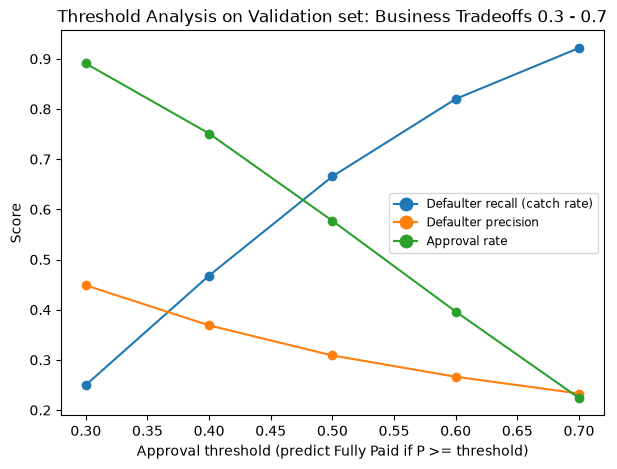

In [ ]:
plt.figure(figsize=(7, 5))
plt.plot(threshold_table["threshold"], threshold_table["defaulter_recall"], marker="o", label="Defaulter recall (catch rate)")
plt.plot(threshold_table["threshold"], threshold_table["defaulter_precision"], marker="o", label="Defaulter precision")
plt.plot(threshold_table["threshold"], threshold_table["approval_rate"], marker="o", label="Approval rate")
plt.xlabel("Approval threshold (predict Fully Paid if P >= threshold)")
plt.ylabel("Score")
plt.title("Threshold Analysis on Validation set: Business Tradeoffs 0.3 - 0.7")
plt.legend(fontsize="small", markerscale=1.5)
plt.show()

## Model Evaluation on Test Dataset

In [ ]:
y_prob = logreg.predict_proba(X_test_scaled)[:, 1]
y_pred_default = logreg.predict(X_test_scaled)

In [ ]:
cm = confusion_matrix(y_test, y_pred_default)
print("Confusion Matrix (rows=actual, cols=predicted) [Charged Off, Fully Paid]:\n", cm)

Confusion Matrix (rows=actual, cols=predicted) [Charged Off, Fully Paid]:
 [[10418  5117]
 [22784 40887]]


Text(0.5, 1.0, 'Confusion Matrix (threshold=0.50)')

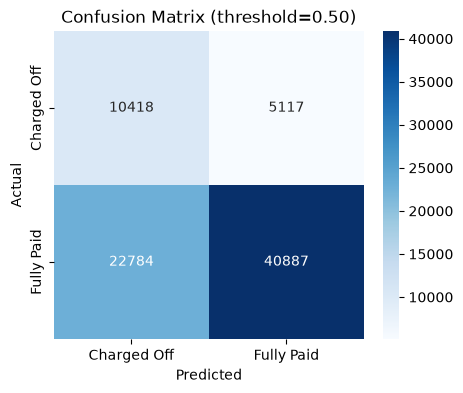

In [ ]:
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Charged Off", "Fully Paid"],
            yticklabels=["Charged Off", "Fully Paid"])
plt.ylabel("Actual"); plt.xlabel("Predicted")
plt.title("Confusion Matrix (threshold=0.50)")

In [ ]:
acc = accuracy_score(y_test, y_pred_default)
prec_fp = precision_score(y_test, y_pred_default, pos_label=1)
rec_fp = recall_score(y_test, y_pred_default, pos_label=1)
f1_fp = f1_score(y_test, y_pred_default, pos_label=1)
prec_co = precision_score(y_test, y_pred_default, pos_label=0)
rec_co = recall_score(y_test, y_pred_default, pos_label=0)
f1_co = f1_score(y_test, y_pred_default, pos_label=0)

print(f"Accuracy:                       {acc:.4f}")
print(f"Precision (Fully Paid=1):       {prec_fp:.4f}")
print(f"Recall    (Fully Paid=1):       {rec_fp:.4f}")
print(f"F1-score  (Fully Paid=1):       {f1_fp:.4f}")
print(f"Precision (Charged Off=0):      {prec_co:.4f}")
print(f"Recall    (Charged Off=0):      {rec_co:.4f}")
print(f"F1-score  (Charged Off=0):      {f1_co:.4f}")

Accuracy:                       0.6477
Precision (Fully Paid=1):       0.8888
Recall    (Fully Paid=1):       0.6422
F1-score  (Fully Paid=1):       0.7456
Precision (Charged Off=0):      0.3138
Recall    (Charged Off=0):      0.6706
F1-score  (Charged Off=0):      0.4275


**Observation:** With class_weight="balanced" and the default 0.50 threshold, the model trades some overall accuracy for a much higher **defaulter recall** (catching more true Charged-Off loans) since for LoanTap the cost of approving a future defaulter (principal loss) is typically higher than the cost of rejecting a would-be good borrower (foregone interest income). Precision on the Charged-Off class is comparatively modest — a direct consequence of prioritizing recall.

In [ ]:
auc = roc_auc_score(y_test, y_prob)
fpr, tpr, roc_thresh = roc_curve(y_test, y_prob)
print(f"ROC AUC Score: {auc:.4f}")

ROC AUC Score: 0.7130


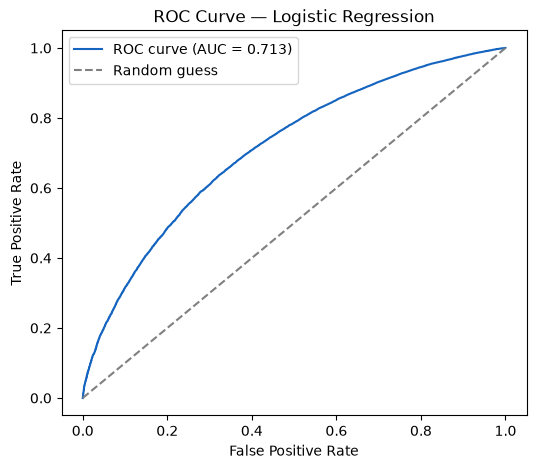

In [ ]:
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {auc:.3f})", color="#1565c0")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random guess")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Logistic Regression")
plt.legend()
plt.show()

**Observation:** An AUC comfortably above 0.5 confirms the model has genuine discriminative power between Fully-Paid and Charged-Off borrowers.

### Precision-Recall curve

In [ ]:
prec, rec, pr_thresh = precision_recall_curve(y_test, y_prob)  # for class "1" (Fully Paid)
ap = average_precision_score(y_test, y_prob)
print(f"Average Precision (Fully Paid class): {ap:.4f}")

Average Precision (Fully Paid class): 0.9028


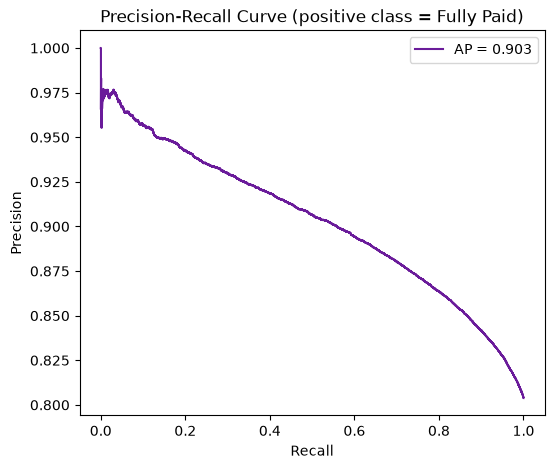

In [ ]:
plt.figure(figsize=(6, 5))
plt.plot(rec, prec, color="#6a1b9a", label=f"AP = {ap:.3f}")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Precision-Recall Curve (positive class = Fully Paid)")
plt.legend()
plt.show()

**Observation:** The precision-recall curve is the informative diagnostic here given the class imbalance. It shows the direct tradeoff LoanTap must navigate: pushing for higher recall of the minority Charged-Off class comes at the cost of precision, i.e. more false positives (good borrowers flagged as risky).

### Precision Recall Tradeoff

In [ ]:
risk_score = 1 - y_prob
prec_d, rec_d, thresh_d = precision_recall_curve(1 - y_test, risk_score)
f1s = 2 * prec_d * rec_d / (prec_d + rec_d + 1e-9)
best_idx = np.argmax(f1s)

In [ ]:
print(f"\nBest F1 threshold for detecting DEFAULTERS: risk_score >= {thresh_d[best_idx]:.3f} "
      f"(precision={prec_d[best_idx]:.3f}, recall={rec_d[best_idx]:.3f}, f1={f1s[best_idx]:.3f})")


Best F1 threshold for detecting DEFAULTERS: risk_score >= 0.527 (precision=0.329, recall=0.620, f1=0.430)


In [ ]:
risk_score = 1 - y_prob
prec_d, rec_d, thresh_d = precision_recall_curve(1 - y_test, risk_score)
f1s = 2 * prec_d * rec_d / (prec_d + rec_d + 1e-9)
best_idx = np.argmax(f1s[:-1])
optimal_risk_threshold = thresh_d[best_idx]
optimal_approval_threshold = 1 - optimal_risk_threshold
print(f"Optimal threshold: risk_score >= {optimal_risk_threshold:.3f} ")
print(f"precision={prec_d[best_idx]:.3f}, recall={rec_d[best_idx]:.3f}, "
      f"f1={f1s[best_idx]:.3f}")

Optimal threshold: risk_score >= 0.527 
precision=0.329, recall=0.620, f1=0.430


In [ ]:
threshold_rows = []
for cutoff in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred_at_cutoff = (y_prob >= cutoff).astype(int)  # 1 = approve (Fully Paid predicted)
    report = classification_report(y_test, pred_at_cutoff, output_dict=True,
                                    target_names=["Charged Off", "Fully Paid"])
    approval_rate = pred_at_cutoff.mean()
    threshold_rows.append({
        "threshold": cutoff,
        "defaulter_precision": report["Charged Off"]["precision"],
        "defaulter_recall": report["Charged Off"]["recall"],
        "fully_paid_precision": report["Fully Paid"]["precision"],
        "fully_paid_recall": report["Fully Paid"]["recall"],
        "fully_paid_f1": report["Fully Paid"]["f1-score"],
        "overall_accuracy": report["accuracy"],
        "approval_rate": approval_rate,
    })

In [ ]:
threshold_table = pd.DataFrame(threshold_rows)
print(threshold_table.to_string(index=False, float_format=lambda v: f"{v:,.3f}"))

 threshold  defaulter_precision  defaulter_recall  fully_paid_precision  fully_paid_recall  fully_paid_f1  overall_accuracy  approval_rate
     0.300                0.452             0.247                 0.835              0.927          0.878             0.794          0.893
     0.400                0.374             0.469                 0.862              0.809          0.835             0.742          0.754
     0.500                0.314             0.671                 0.889              0.642          0.746             0.648          0.581
     0.600                0.268             0.821                 0.912              0.454          0.606             0.526          0.400
     0.700                0.234             0.925                 0.934              0.261          0.408             0.391          0.224


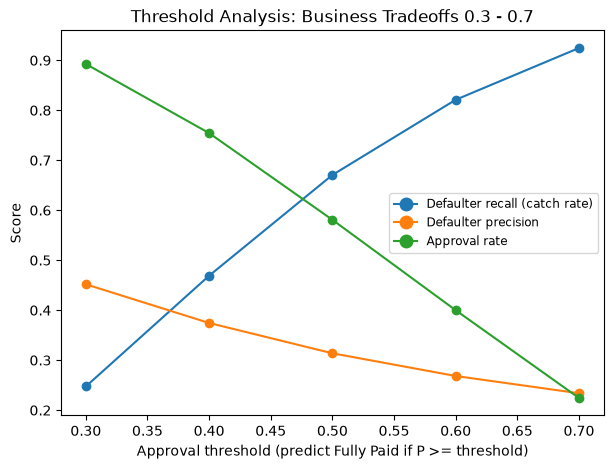

In [ ]:
plt.figure(figsize=(7, 5))
plt.plot(threshold_table["threshold"], threshold_table["defaulter_recall"], marker="o", label="Defaulter recall (catch rate)")
plt.plot(threshold_table["threshold"], threshold_table["defaulter_precision"], marker="o", label="Defaulter precision")
plt.plot(threshold_table["threshold"], threshold_table["approval_rate"], marker="o", label="Approval rate")
plt.xlabel("Approval threshold (predict Fully Paid if P >= threshold)")
plt.ylabel("Score")
plt.title("Threshold Analysis: Business Tradeoffs 0.3 - 0.7")
plt.legend(fontsize="small", markerscale=1.5)
plt.show()

**Explanation of each threshold:**

- **Threshold = 0.3 (very lenient approval):** Almost everyone gets approved. Approval rate is
  highest, but defaulter recall is lowest — LoanTap approves many borrowers who will later
  charge off. Good for growth/volume, bad for portfolio credit quality. Suited to a
  high-risk-appetite, high-yield product strategy.
- **Threshold = 0.4:** Slightly more selective than 0.3. Marginal improvement in catching
  defaulters, still a high approval rate. Reasonable for a growth-oriented but not reckless
  policy.
- **Threshold = 0.5 (default / balanced):** The standard midpoint. Reasonable balance between
  approval volume and risk-catching, and the natural starting point before business-specific
  tuning.
- **Threshold = 0.6 (more conservative):** Noticeably higher defaulter recall and precision at
  the cost of rejecting more borrowers who would actually have repaid. Appropriate when the cost
  of a bad loan (charge-off) clearly outweighs the opportunity cost of a rejected good loan —
  which is usually true for unsecured personal loans.
- **Threshold = 0.7 (very conservative):** Approval rate drops substantially; the model becomes
  highly selective, approving only the safest applicants. Best defaulter recall/precision, but
  risks over-rejecting genuinely creditworthy customers and shrinking loan volume/revenue too
  aggressively.

**Recommendation:** For an unsecured personal-loan book, a threshold in the **0.55-0.60 range**
is a reasonable operating point — it meaningfully improves defaulter capture over the naive 0.5
cutoff without collapsing approval volume the way 0.7 would.

## Handling Imbalance in the Data

In [ ]:
def apply_smote(X_train_in, y_train_in, random_state=42):

    sm = SMOTE(random_state=random_state)
    X_res, y_res = sm.fit_resample(X_train_in, y_train_in)
    return X_res, y_res

In [ ]:
def apply_random_oversample(X_train_in, y_train_in, random_state=42):

    ros = RandomOverSampler(random_state=random_state)
    X_res, y_res = ros.fit_resample(X_train_in, y_train_in)
    return X_res, y_res

In [ ]:
def apply_random_undersample(X_train_in, y_train_in, random_state=42):
    '''Random undersampling via imblearn.under_sampling.RandomUnderSampler.'''
    rus = RandomUnderSampler(random_state=random_state)
    X_res, y_res = rus.fit_resample(X_train_in, y_train_in)
    return X_res, y_res

In [ ]:
print("Original training class distribution:\n", y_train.value_counts(), "\n")

X_train_smote, y_train_smote = apply_smote(X_train_scaled, y_train)
print("After SMOTE:\n", y_train_smote.value_counts())

X_train_over, y_train_over = apply_random_oversample(X_train_scaled, y_train)
print("\nAfter Random Oversampling:\n", y_train_over.value_counts())

X_train_under, y_train_under = apply_random_undersample(X_train_scaled, y_train)
print("\nAfter Random Undersampling:\n", y_train_under.value_counts())

Original training class distribution:
 loan_repaid
1    191015
0     46603
Name: count, dtype: int64 

After SMOTE:
 loan_repaid
0    191015
1    191015
Name: count, dtype: int64

After Random Oversampling:
 loan_repaid
0    191015
1    191015
Name: count, dtype: int64

After Random Undersampling:
 loan_repaid
0    46603
1    46603
Name: count, dtype: int64


In [ ]:
def train_and_evaluate(X_tr, y_tr, X_te, y_te, label, use_class_weight=False):
    model = LogisticRegression(max_iter=2000, random_state=42,
                                class_weight="balanced" if use_class_weight else None)
    model.fit(X_tr, y_tr)
    prob = model.predict_proba(X_te)[:, 1]
    pred = model.predict(X_te)
    report = classification_report(y_te, pred, output_dict=True, target_names=["Charged Off", "Fully Paid"])
    auc = roc_auc_score(y_te, prob)
    row = {
        "method": label,
        "accuracy": report["accuracy"],
        "defaulter_precision": report["Charged Off"]["precision"],
        "defaulter_recall": report["Charged Off"]["recall"],
        "defaulter_f1": report["Charged Off"]["f1-score"],
        "fully_paid_precision": report["Fully Paid"]["precision"],
        "fully_paid_recall": report["Fully Paid"]["recall"],
        "fully_paid_f1": report["Fully Paid"]["f1-score"],
        "roc_auc": auc,
    }
    return row, model

results = []
row_base, model_base = train_and_evaluate(X_train_scaled, y_train, X_test_scaled, y_test,
                                           "Baseline (class_weight=balanced, no resampling)", use_class_weight=True)
results.append(row_base)

row_unweighted, _ = train_and_evaluate(X_train_scaled, y_train, X_test_scaled, y_test,
                                        "Baseline (no weighting, no resampling)", use_class_weight=False)
results.append(row_unweighted)

row_smote, model_smote = train_and_evaluate(X_train_smote, y_train_smote, X_test_scaled, y_test, "SMOTE")
results.append(row_smote)

row_over, _ = train_and_evaluate(X_train_over, y_train_over, X_test_scaled, y_test, "Random Oversampling")
results.append(row_over)

row_under, _ = train_and_evaluate(X_train_under, y_train_under, X_test_scaled, y_test, "Random Undersampling")
results.append(row_under)

resampling_comparison = pd.DataFrame(results)
print(resampling_comparison.to_string(index=False, float_format=lambda v: f"{v:,.4f}"))

                                         method  accuracy  defaulter_precision  defaulter_recall  defaulter_f1  fully_paid_precision  fully_paid_recall  fully_paid_f1  roc_auc
Baseline (class_weight=balanced, no resampling)    0.6478               0.3138            0.6707        0.4276                0.8888             0.6421         0.7456   0.7130
         Baseline (no weighting, no resampling)    0.8058               0.5477            0.0558        0.1013                0.8110             0.9888         0.8911   0.7129
                                          SMOTE    0.6485               0.3134            0.6653        0.4261                0.8875             0.6444         0.7467   0.7111
                            Random Oversampling    0.6475               0.3141            0.6738        0.4285                0.8895             0.6411         0.7451   0.7129
                           Random Undersampling    0.6466               0.3133            0.6726        0.4275          

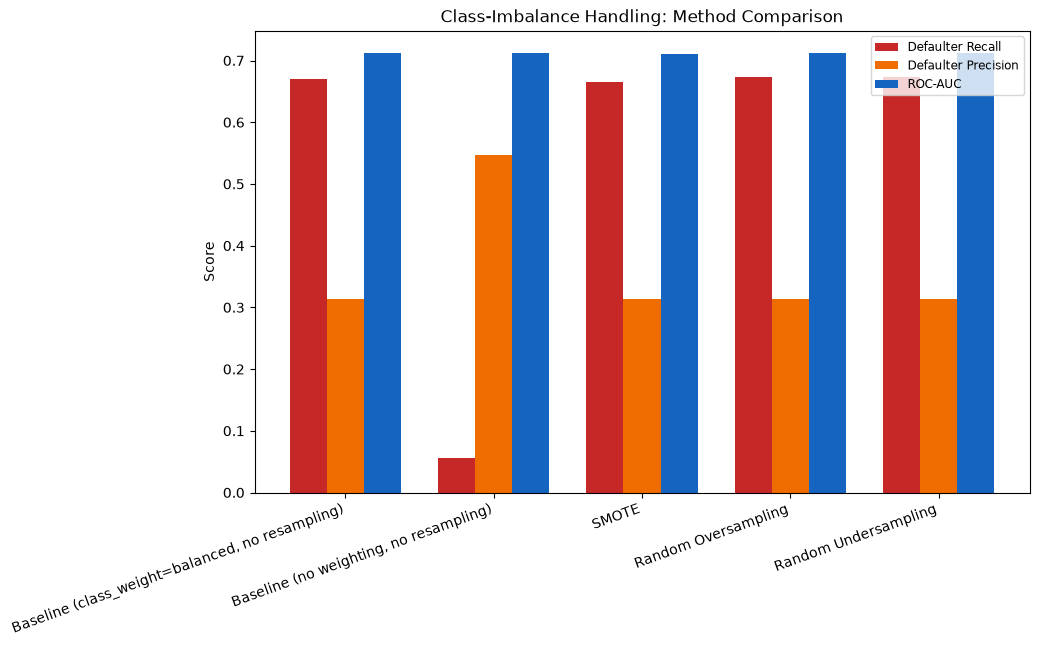

In [ ]:
plt.figure(figsize=(10, 6))
x = np.arange(len(resampling_comparison))
width = 0.25
plt.bar(x - width, resampling_comparison["defaulter_recall"], width, label="Defaulter Recall", color="#c62828")
plt.bar(x, resampling_comparison["defaulter_precision"], width, label="Defaulter Precision", color="#ef6c00")
plt.bar(x + width, resampling_comparison["roc_auc"], width, label="ROC-AUC", color="#1565c0")
plt.xticks(x, resampling_comparison["method"], rotation=20, ha="right")
plt.ylabel("Score")
plt.title("Class-Imbalance Handling: Method Comparison")
plt.legend(fontsize="small", markerscale=1.5)
plt.show()

**Observation:** All five configurations produce **essentially the same ROC-AUC** (~0.71), since ROC-AUC is threshold- and prevalence-independent and mainly reflects ranking ability, which resampling doesn't fundamentally change for a well-specified linear model.
Where the methods differ sharply is versus the **unweighted baseline**: with no imbalance handling at all, defaulter recall collapses to just **0.056** (the model essentially always predicts the majority "Fully Paid" class, hitting 80.6% accuracy while catching almost no true
defaulters).

## Executive Summary

### Overall Observations

1. 80.39% of borrowers in this portfolio Fully Paid their loan; 19.61% Charged Off.
2. Installment is a function of loan_amnt, int_rate and term, which is exactly why loan_amnt was dropped.(r = 0.954)
3. 'MORTGAGE' is the most common home-ownership status (198,348 borrowers, 50.1% of the portfolio), followed by 'RENT'.
4. Grade A borrowers Fully Pay at ~93.71%, the highest of any grade, confirming LoanTap's own grade assignment is strongly aligned with actual outcomes.
5. 'Teacher', 'Manager', 'Registered Nurse', 'RN', 'Supervisor' are the five most common job titles - however emp_title's extreme cardinality (thousands of free-text values) makes it unsuitable as a modeling feature without heavy grouping, so it was excluded from analysis.
6. Given LoanTap's business objective (minimize bad debt while preserving loan volume), the single most important metric is DEFAULTER RECALL on the Charged-Off class, because missing a true defaulter (a false negative here) costs LoanTap the full outstanding principal, whereas rejecting a would-be good borrower (a false positive) only costs foregone interest margin. ROC-AUC is the best threshold-independent summary of overall discriminative power, but RECALL at a business-chosen threshold is what should drive the underwriting decision itself.
7. Precision vs Recall: Recall answers all the loans that will actually default. For an unsecured personal-loan lender, RECALL is generally prioritized over precision because false negatives (approved defaulters) are far more costly than false positives (rejected good borrowers) - but recall cannot be pushed to the extreme, since very high recall comes at the cost of precision dropping, meaning too many genuinely creditworthy customers get rejected and LoanTap loses revenue and market share.
8. Most Important Features are : 'sub_grade_C5', 'sub_grade_C4', 'sub_grade_D1', 'sub_grade_C3', 'sub_grade_D2', 'sub_grade_D4', 'sub_grade_C2', 'sub_grade_D3'. These fall into three groups: (a) credit-grade indicators (sub_grade dummies), (b) loan-structure variables (term_num, installment), and (c) borrower financial-health variables (dti, revol_util, annual_inc, credit_history_years).
9. Geographical impact: zip-code analysis shows an artificially strong, near-perfect link between a handful of zip codes and default status. Geoghraphical columns were excluded from the model, as it is redundant with existing features and because using zip/city/state as an underwriting input creates lending risk- this could cause legal issues.

### Business Insights

1. Higher interest rates significantly increase default probability.
2. Lower grades (D–G) are associated with substantially higher credit risk.
3. Longer loan terms (60 months) show greater default rates than shorter terms.
4. Higher DTI ratios correlate with increased defaults.
5. Borrowers with repeated delinquencies exhibit elevated risk.

### Business Recommendations

1. Prefer Grade A/B customers for standard, low-friction approval - they show the highest historical repayment rates and the lowest model-predicted risk.
2. Evaluate Grade E/F/G applicants with additional manual underwriting steps (income verification, higher documentation) rather than blanket rejection, since some are still creditworthy despite the lower average repayment rate for the grade.
3. Increase scrutiny for high-DTI applicants - dti is a top-15 driver of default risk; consider a maximum DTI cap or mandatory income re-verification above chosen DTI threshold.
4. Lower approval rates require extra collateral or a co-signer for applicants with multiple public-record bankruptcies.
5. Apply higher monitoring and possibly lower credit limits for high revolving-utilization, since high utilization is associated with financial stress and is one of the stronger risk-raising features.
6. Make income verification mandatory for all applicants above a chosen loan-amount or DTI threshold, since verification status correlates with repayment reliability and is checkable at application time.
7. Adopt threshold optimization using the Precision-Recall Curve rather than keeping the default 0.5 cutoff - move the approval threshold to roughly 0.55-0.60 to materially improve defaulter recall without collapsing approval volume.
10. Apply a different approval policy for 36-month vs 60-month loans. 60-month loans show a meaningfully lower repayment rate and term_num is a top risk-raising feature; consider a stricter score cutoff or added pricing premium for 60-month terms.
11. Segment customers into risk tiers (e.g. Low / Medium / High) using the model's predicted probability, and apply tier-specific approval, pricing, and monitoring rules instead of a single uniform policy.
12. Introduce risk-based pricing - charge higher interest rates to applicants in the higher-predicted-risk bands (rather than relying solely on approve/reject), which lets LoanTap still serve riskier segments profitably instead of excluding them entirely.
13. Build an early-warning system that scores existing (already-disbursed) loans periodically using updated bureau data, flagging accounts whose risk profile has deteriorated (e.g. rising revol_util, new derogatory marks) for proactive outreach or restructuring before they default.
14. Track and re-validate the model's ROC-AUC and defaulter recall on a rolling basis (e.g. quarterly) as model trained on historical data can drift out of calibration.
15. Don't use zip_code, city, or state as underwriting inputs - the geographic signal in this dataset is an artificial artifact and, more importantly, using raw geography as a credit input creates compliance risk.
16. Cap or investigate extreme annual_inc and revol_bal values at intake - unusually high self-reported income is a known fraud vector and warrants a verification step.
17. Use credit_history_years as a positive underwriting signal - longer credit history is one of the stronger repayment-supporting features and can support faster/lighter-touch approval for long-tenure applicants.
18. For borderline applicants (predicted probability close to the chosen threshold), choose manual underwriting review rather than an automatic reject, since the model's error rate is highest exactly in this probability band.
19. Reconsider or restrict very large loan amounts for lower sub-grades - the combination of high loan_amnt/installment burden and a weak sub-grade compounds default risk.
20. Periodically retrain with SMOTE or class-weighting as the default portfolio grows, and A/B test threshold changes on a held-out slice of new originations before rolling out portfolio-wide.
21. Pair the model's approve/reject decision with a clear reason code (top contributing features from the coefficient table) for every rejection, both for regulatory transparency and for applicant-facing communication.
22. Combine the model score with LoanTap's existing grade/sub_grade system rather than replacing it outright - grade already reflects substantial underwriting expertise and the model's top features corroborate rather than contradict it, so the two should be used together.